In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import os

from src.config import (
    PROCESSED_DATA_DIR, DEFAULT_FINETUNED_MODEL_DIR,
    MODELS_DIR, FIGURES_DIR, METRICS_DIR,
    BASE_MODEL_NAME, ID_TO_LABEL, LABEL_TO_ID,
    RANDOM_SEED, LEARNING_RATE, TRAIN_BATCH_SIZE,
    EVAL_BATCH_SIZE, WEIGHT_DECAY, NUM_TRAIN_EPOCHS,
)
from src.baseline import run_zero_shot_baseline
from src.inference import load_fine_tuned_model, predict_sentiment_batch
from src.per_class_evaluation import compute_per_class_f1, plot_per_class_f1
from src.weighted_trainer import get_class_weights, WeightedLossTrainer
from src.preprocessing import dataframe_to_hf_dataset, tokenize_hf_dataset, add_label_ids
from src.evaluate import compute_trainer_metrics, calculate_metrics

WEIGHTED_MODEL_DIR = MODELS_DIR / 'distilbert_weighted'
WEIGHTED_MODEL_DIR.mkdir(parents=True, exist_ok=True)

c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
test_df = pd.read_csv(PROCESSED_DATA_DIR / 'test.csv')
print(f'Test set size: {len(test_df)}')
print(f'Label distribution:\n{test_df["label"].value_counts()}')
true_labels = test_df['label'].tolist()

Test set size: 726
Label distribution:
label
neutral     431
positive    204
negative     91
Name: count, dtype: int64


In [3]:
zs_metrics, zs_results_df = run_zero_shot_baseline(test_df)
zs_preds = zs_results_df['predicted_label'].tolist()
zs_f1 = compute_per_class_f1(true_labels, zs_preds)
print('Zero-shot per-class F1:', zs_f1)
print('Zero-shot overall:', zs_metrics)

Zero-shot Evaluation: 100%|██████████| 46/46 [3:34:18<00:00, 279.54s/it]    


Zero-shot per-class F1: {'negative': 0.6980392156862745, 'neutral': 0.18448637316561844, 'positive': 0.5416666666666666}
Zero-shot overall: {'accuracy': 0.4518, 'macro_f1': 0.4747, 'per_class_f1': {'negative': 0.698, 'neutral': 0.1845, 'positive': 0.5417}, 'model': 'facebook/bart-large-mnli', 'evaluation_split': 'held-out test set', 'num_examples': 726}


In [4]:
model, tokenizer, device = load_fine_tuned_model(DEFAULT_FINETUNED_MODEL_DIR)
ft_labels, ft_probs, ft_confs, ft_scores = predict_sentiment_batch(
    texts=test_df['sentence'].tolist(),
    model=model,
    tokenizer=tokenizer,
    device=device,
)
ft_f1 = compute_per_class_f1(true_labels, ft_labels)
ft_metrics = calculate_metrics(true_labels, ft_labels)
print('Fine-tuned per-class F1:', ft_f1)
print('Fine-tuned overall:', ft_metrics)

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1127.89it/s]


Fine-tuned per-class F1: {'negative': 0.8393782383419689, 'neutral': 0.8870779976717112, 'positive': 0.79}
Fine-tuned overall: {'accuracy': 0.854, 'macro_f1': 0.8388, 'per_class_f1': {'negative': 0.8394, 'neutral': 0.8871, 'positive': 0.79}}


Figure saved to C:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\outputs\figures\per_class_f1_baseline_vs_finetuned.png


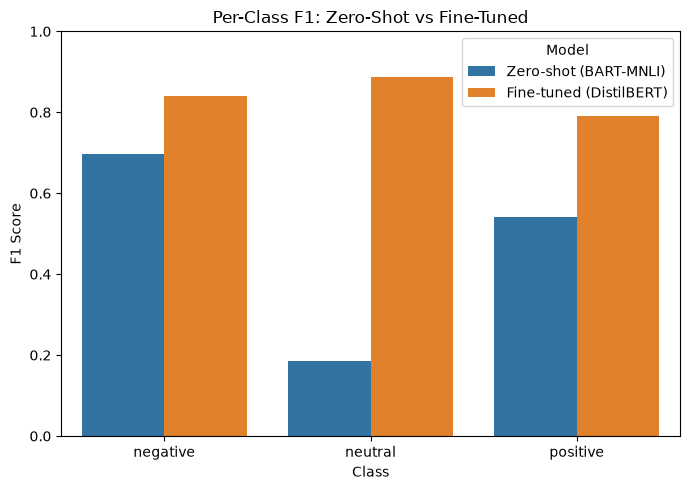

In [5]:
plot_per_class_f1(
    f1_a=zs_f1,
    f1_b=ft_f1,
    label_a='Zero-shot (BART-MNLI)',
    label_b='Fine-tuned (DistilBERT)',
    title='Per-Class F1: Zero-Shot vs Fine-Tuned',
    save_path=str(FIGURES_DIR / 'per_class_f1_baseline_vs_finetuned.png'),
)

In [8]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    set_seed,
)

set_seed(RANDOM_SEED)

train_df = pd.read_csv(PROCESSED_DATA_DIR / 'train.csv')
val_df = pd.read_csv(PROCESSED_DATA_DIR / 'validation.csv')

class_weight_tensor = get_class_weights(train_df)
print('Class weights (negative, neutral, positive):', class_weight_tensor)

train_df_ids = add_label_ids(train_df)
val_df_ids = add_label_ids(val_df)

train_ds = dataframe_to_hf_dataset(train_df_ids)
val_ds = dataframe_to_hf_dataset(val_df_ids)

w_tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_NAME)
tok_train = tokenize_hf_dataset(train_ds, w_tokenizer)
tok_val = tokenize_hf_dataset(val_ds, w_tokenizer)

w_model = AutoModelForSequenceClassification.from_pretrained(
    BASE_MODEL_NAME,
    num_labels=len(ID_TO_LABEL),
    id2label=ID_TO_LABEL,
    label2id=LABEL_TO_ID,
)

data_collator = DataCollatorWithPadding(tokenizer=w_tokenizer)

training_args = TrainingArguments(
    output_dir=str(WEIGHTED_MODEL_DIR / 'checkpoints'),
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    num_train_epochs=NUM_TRAIN_EPOCHS,
    weight_decay=WEIGHT_DECAY,
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    logging_steps=50,
    seed=RANDOM_SEED,
    report_to='none',
)

trainer = WeightedLossTrainer(
    model=w_model,
    args=training_args,
    train_dataset=tok_train,
    eval_dataset=tok_val,
    processing_class=w_tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_trainer_metrics,
    class_weight_tensor=class_weight_tensor,
)

print('Starting weighted-loss training...')
trainer.train()

w_model.save_pretrained(WEIGHTED_MODEL_DIR)
w_tokenizer.save_pretrained(WEIGHTED_MODEL_DIR)
print(f'Weighted model saved to {WEIGHTED_MODEL_DIR}')

Class weights (negative, neutral, positive): tensor([2.6675, 0.5616, 1.1840])


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2446.89it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting weighted-loss training...


c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.520183,0.470215,0.816600,0.789600
2,0.319638,0.443610,0.815200,0.807000
3,0.195072,0.453599,0.819300,0.799700


Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.06s/it]
c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:01<00:00,  1.16s/it]
c:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.62it/s]

Weighted model saved to C:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\models\distilbert_weighted


In [9]:
w_model_eval, w_tok_eval, w_device = load_fine_tuned_model(WEIGHTED_MODEL_DIR)
w_labels, w_probs, w_confs, w_scores = predict_sentiment_batch(
    texts=test_df['sentence'].tolist(),
    model=w_model_eval,
    tokenizer=w_tok_eval,
    device=w_device,
)
w_f1 = compute_per_class_f1(true_labels, w_labels)
w_metrics = calculate_metrics(true_labels, w_labels)
print('Weighted-loss per-class F1:', w_f1)
print('Weighted-loss overall:', w_metrics)

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1781.28it/s]


Weighted-loss per-class F1: {'negative': 0.8601036269430051, 'neutral': 0.8282051282051283, 'positive': 0.7432150313152401}
Weighted-loss overall: {'accuracy': 0.8044, 'macro_f1': 0.8105, 'per_class_f1': {'negative': 0.8601, 'neutral': 0.8282, 'positive': 0.7432}}


Figure saved to C:\Users\sarth\OneDrive\Desktop\Plasksha Work\Python\time-aware-financial-news-monitor\outputs\figures\per_class_f1_standard_vs_weighted.png


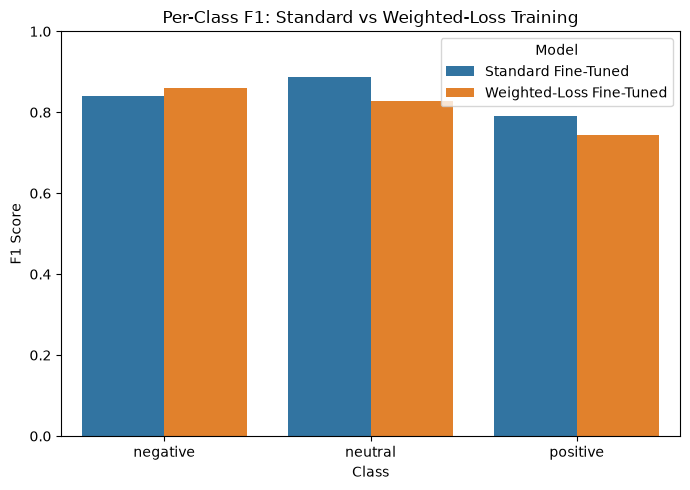

In [10]:
plot_per_class_f1(
    f1_a=ft_f1,
    f1_b=w_f1,
    label_a='Standard Fine-Tuned',
    label_b='Weighted-Loss Fine-Tuned',
    title='Per-Class F1: Standard vs Weighted-Loss Training',
    save_path=str(FIGURES_DIR / 'per_class_f1_standard_vs_weighted.png'),
)

In [11]:
summary = pd.DataFrame({
    'Class': ['negative', 'neutral', 'positive'],
    'Zero-Shot F1': [zs_f1['negative'], zs_f1['neutral'], zs_f1['positive']],
    'Fine-Tuned F1': [ft_f1['negative'], ft_f1['neutral'], ft_f1['positive']],
    'Weighted F1': [w_f1['negative'], w_f1['neutral'], w_f1['positive']],
})
print(summary.to_string(index=False))
print()
print(f'Overall Accuracy  -> Zero-shot: {zs_metrics["accuracy"]:.4f}  |  Fine-tuned: {ft_metrics["accuracy"]:.4f}  |  Weighted: {w_metrics["accuracy"]:.4f}')
print(f'Overall Macro F1  -> Zero-shot: {zs_metrics["macro_f1"]:.4f}  |  Fine-tuned: {ft_metrics["macro_f1"]:.4f}  |  Weighted: {w_metrics["macro_f1"]:.4f}')

   Class  Zero-Shot F1  Fine-Tuned F1  Weighted F1
negative      0.698039       0.839378     0.860104
 neutral      0.184486       0.887078     0.828205
positive      0.541667       0.790000     0.743215

Overall Accuracy  -> Zero-shot: 0.4518  |  Fine-tuned: 0.8540  |  Weighted: 0.8044
Overall Macro F1  -> Zero-shot: 0.4747  |  Fine-tuned: 0.8388  |  Weighted: 0.8105
